In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 13.2 — Lie-algebra action and intertwiner

Source: SMSA version 7.8 (2026-11-05), `smsa.pdf`. This notebook translates the named formulas; it does not replace their discussion in SMSA. Native DisCoPy figures below read **top to bottom**, whereas SMSA reads bottom to top. Tensor factors retain their left-to-right order. `f >> g` means $g\circ f$. Tensor arrays list input axes before output axes; a conventional column matrix is supplied transposed. Checks print computed objects and residuals and do not stop execution on a failed equality.

Graphical calculus 13.2.13, (13.19)–(13.20). The action coupon has two inputs, $\mathfrak g$ and $V$. We use the defining two-dimensional $\mathfrak{sl}_2$ action in the ordered basis $(H,E,F)$, and the intertwiner $\phi=2\,\mathrm{id}_V$. This is a concrete instance of the same source diagram, with $W=V$.

In [1]:
from discopy import symmetric, tensor
import numpy as np

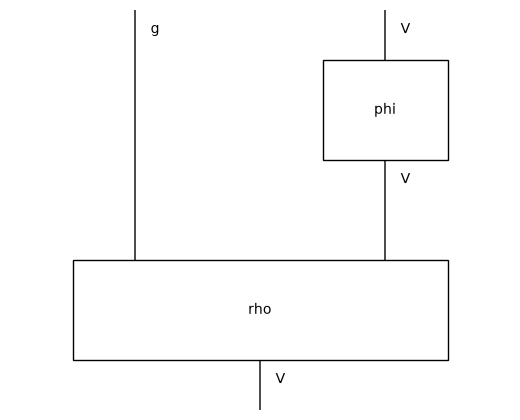

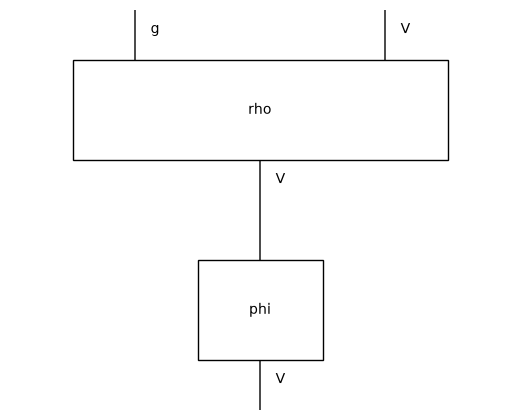

In [2]:
g, V = symmetric.Ty('g'), symmetric.Ty('V')
rho = symmetric.Box('rho', g @ V, V)
phi = symmetric.Box('phi', V, V)
left = (symmetric.Id(g) @ phi) >> rho
right = rho >> phi
left.draw(figsize=(5, 4))
right.draw(figsize=(5, 4))

In [3]:
H = np.array([[1,0],[0,-1]])
E = np.array([[0,1],[0,0]])
Fm = np.array([[0,0],[1,0]])
action = np.stack([H.T, E.T, Fm.T])
F = tensor.Functor({g: tensor.Dim(3), V: tensor.Dim(2)}, {rho: action, phi: 2*np.eye(2,dtype=int)}, dom=symmetric.Category, dtype=int)
print('(13.20): arrays indexed by Lie basis, input V, output V')
print('left =', F(left).array)
print('right =', F(right).array)
print('difference =', F(left).array-F(right).array)
print('equal =', F(left) == F(right))

(13.20): arrays indexed by Lie basis, input V, output V
left = [[[ 2  0]
  [ 0 -2]]

 [[ 0  0]
  [ 2  0]]

 [[ 0  2]
  [ 0  0]]]
right = [[[ 2  0]
  [ 0 -2]]

 [[ 0  0]
  [ 2  0]]

 [[ 0  2]
  [ 0  0]]]
difference = [[[0 0]
  [0 0]]

 [[0 0]
  [0 0]]

 [[0 0]
  [0 0]]]
equal = True
